# EKSPLORASI VISUALISASI DATA DAN VISUAL LABELING DATASET KARYAWAN

## Deskripsi Karakteristik Database dan Pemetaan Pola Variabel
Dataset yang digunakan dalam penelitian ini adalah **`karyawan_bersih_300.xlsx`** yang terdiri atas **300 baris data (observasi)** dan **8 atribut**. Dataset karyawan ini merupakan data *cross-sectional* (potret kondisi sumber daya manusia pada satu waktu).

1. **Atribut Identitas (*Unique Identifier*) :**
   * **`id_karyawan`** (`int64`): Nomor identitas karyawan (rentang 1 s.d. 300). Digunakan sebagai kunci penghitung jumlah observasi (`count`).
   * **`nama`** (`object/string`): Nama lengkap karyawan. Digunakan sebagai informasi pelengkap.

2. **Atribut Kategorikal (*Categorical Variables*) — Mengelompokkan Data:**
   * **`jenis_kelamin`** (`object`): Kategori gender karyawan yang terdiri atas 2 nilai, yaitu **`L`** (Laki-laki: 176 orang) dan **`P`** (Perempuan: 124 orang).
   * **`departemen`** (`object`): Kategori unit kerja yang terdiri atas 9 divisi (Administrasi, Finance, Operasional, Sales, Produksi, IT, R&D, HR, dan Marketing).
   * **`jabatan`** (`object`): Kategori tingkatan posisi struktural (Staff, Admin, Supervisor, dan Manager). Atribut ini bersifat *ordinal* (memiliki urutan hirarki).
   * **`kota_asal`** (`object`): Kategori geografis domisili asal karyawan.

3. **Atribut Numerik / Metrik (*Numerical Variables*) — Nilai yang Dihitung & Diukur:**
   * **`umur`** (`int64`): Usia karyawan dalam satuan tahun (rentang 18 s.d. 64 tahun, rata-rata 42,53 tahun).
   * **`gaji`** (`object` $\rightarrow$ dikonversi ke `int64`): Nominal kompensasi bulanan karyawan. Karena masih tersimpan sebagai teks bermata uang (`Rp4.750.000`), atribut ini wajib dikonversi menjadi tipe numerik (`gaji_numerik`) sebelum diolah ke dalam grafik.

# 1. IMPORT LIBRARY

In [34]:
import os      # Pengelolaan lokasi path penyimpanan file
import re      # Regular Expression untuk memfilter karakter teks mata uang

import numpy as np             # Operasi komputasi array numerik
import pandas as pd            # Manipulasi data tabular (DataFrame)
import matplotlib.pyplot as plt  # Library dasar visualisasi grafik
import seaborn as sns          # Visualisasi statistik (Histogram, Box Plot, dll)
import plotly.express as px    # Visualisasi interaktif berbasis web

# 3. Konfigurasi Tampilan
%matplotlib inline
sns.set_theme(style="whitegrid")

# 2. MENGHUBUNGKAN GOOGLE COLAB DENGAN GOOGLE DRIVE

In [35]:
from google.colab import drive

# Menghubungkan (mount) penyimpanan Google Drive ke dalam sesi mesin virtual Google Colab
drive.mount('/content/drive')

# Mendefinisikan jalur lokasi (file path) dataset di Google Drive
# Catatan: Sesuaikan path folder di bawah ini dengan struktur folder Google Drive Anda
file_path = '/content/drive/MyDrive/Data Maining 2026/Data Visualization/karyawan_bersih_300.xlsx'

# Membaca file Excel menggunakan engine 'openpyxl' dan menyimpannya ke dalam variabel DataFrame 'data'
data = pd.read_excel(file_path, engine='openpyxl')

# Menampilkan ukuran dimensi dataset (jumlah baris dan kolom) serta keseluruhan ringkasan tabel
print('Ukuran dataset awal: %d baris dan %d kolom\n' % data.shape)
print(data)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ukuran dataset awal: 300 baris dan 8 kolom

     id_karyawan                nama jenis_kelamin  umur    departemen  \
0              1   Slamet Pratama Ii             P    50           R&D   
1              2          Nina Putra             P    22         Sales   
2              3   Luthfi Kusuma Iii             P    25       Finance   
3              4        Rio Iskandar             P    47  Administrasi   
4              5           Putra Eka             P    62      Produksi   
..           ...                 ...           ...   ...           ...   
295          296      Slamet Ningsih             P    62  Administrasi   
296          297        Andi Santoso             L    22  Administrasi   
297          298     Putri Kurniawan             L    22  Administrasi   
298          299        Hartono Sari             P    46  Administrasi   
299          

# 3. CEK STRUKTUR DATA DAN STATISTIK DESKRIPTIF

In [36]:
# Memeriksa indeks baris, nama kolom, jumlah data tidak kosong (Non-Null Count),
# serta tipe data (Dtype) untuk mengidentifikasi kolom mana yang siap divisualisasikan
print("=== INFORMASI STRUKTUR TIPE DATA ===")
data.info()

print("\n=== RINGKASAN STATISTIK DESKRIPTIF AWAL ===")
# Menampilkan statistik deskriptif baik untuk kolom numerik (mean, std, min, kuartil, max)
# maupun kolom bertipe object/kategorikal (unique, top, freq)
display(data.describe(include='all'))

=== INFORMASI STRUKTUR TIPE DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_karyawan    300 non-null    int64 
 1   nama           300 non-null    object
 2   jenis_kelamin  300 non-null    object
 3   umur           300 non-null    int64 
 4   departemen     300 non-null    object
 5   jabatan        300 non-null    object
 6   kota_asal      300 non-null    object
 7   gaji           300 non-null    object
dtypes: int64(2), object(6)
memory usage: 18.9+ KB

=== RINGKASAN STATISTIK DESKRIPTIF AWAL ===


,id_karyawan,nama,jenis_kelamin,umur,departemen,jabatan,kota_asal,gaji
count,300.000000,300,300,300.000000,300,300,300,300
unique,NaN,261,2,NaN,9,4,20,34
top,NaN,Eka Kurniawan,L,NaN,Administrasi,Staff,Jakarta,Rp4.500.000
freq,NaN,3,176,NaN,136,268,46,245
mean,150.323333,NaN,NaN,42.530000,NaN,NaN,NaN,NaN
std,86.690154,NaN,NaN,14.248479,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,18.000000,NaN,NaN,NaN,NaN
25%,75.750000,NaN,NaN,29.750000,NaN,NaN,NaN,NaN
50%,150.500000,NaN,NaN,43.000000,NaN,NaN,NaN,NaN
75%,225.250000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN


# 4. CEK MISSING VALUE DAN DATA DUPLIKAT

In [37]:
# 1. Mengecek jumlah nilai yang kosong (Null/NaN) pada setiap kolom
print("=== JUMLAH MISSING VALUE PER KOLOM ===")
print(data.isnull().sum())

# 2. Mengecek dan Menghapus baris data yang duplikat
jumlah_duplikat = data.duplicated().sum()
print("\nJumlah baris data duplikat awal:", jumlah_duplikat)

if jumlah_duplikat > 0:
    # PERBAIKAN: Menampilkan baris duplikat terlebih dahulu untuk verifikasi
    print("\n--- Daftar Baris yang Terdeteksi Duplikat (untuk verifikasi) ---")
    display(data[data.duplicated(keep=False)].sort_values(by=list(data.columns)))

    # Mengecek apakah id_karyawan juga terduplikasi (seharusnya unik)
    id_duplikat = data[data.duplicated(subset='id_karyawan', keep=False)]
    if len(id_duplikat) > 0:
        print(f"\n⚠️ Perhatian: Terdapat {len(id_duplikat)} baris dengan id_karyawan yang sama.")
        display(id_duplikat)

    # Menghapus duplikat dan mereset indeks agar bersih
    data = data.drop_duplicates().reset_index(drop=True)
    print(f"\n✅ Duplikat dibersihkan. Jumlah baris data setelah dibersihkan: {len(data)}")
else:
    print("\n✅ Tidak ditemukan baris data duplikat.")

=== JUMLAH MISSING VALUE PER KOLOM ===
id_karyawan      0
nama             0
jenis_kelamin    0
umur             0
departemen       0
jabatan          0
kota_asal        0
gaji             0
dtype: int64

Jumlah baris data duplikat awal: 5

--- Daftar Baris yang Terdeteksi Duplikat (untuk verifikasi) ---


,id_karyawan,nama,jenis_kelamin,umur,departemen,jabatan,kota_asal,gaji
16,17,Budi Kurniawan,L,62,Administrasi,Staff,Depok,Rp5.449.170
123,17,Budi Kurniawan,L,62,Administrasi,Staff,Depok,Rp5.449.170
22,23,Andi Prasetyo,L,46,Operasional,Staff,Surabaya,Rp4.500.000
288,23,Andi Prasetyo,L,46,Operasional,Staff,Surabaya,Rp4.500.000
43,138,Tito Putra Jr,L,43,Finance,Staff,Jakarta,Rp4.500.000
137,138,Tito Putra Jr,L,43,Finance,Staff,Jakarta,Rp4.500.000
23,248,Ayu Sari,L,41,Produksi,Staff,Makassar,Rp4.500.000
247,248,Ayu Sari,L,41,Produksi,Staff,Makassar,Rp4.500.000
289,292,Rahma Rafi51,L,53,Produksi,Staff,Jakarta,Rp4.500.000
291,292,Rahma Rafi51,L,53,Produksi,Staff,Jakarta,Rp4.500.000



⚠️ Perhatian: Terdapat 10 baris dengan id_karyawan yang sama.


,id_karyawan,nama,jenis_kelamin,umur,departemen,jabatan,kota_asal,gaji
16,17,Budi Kurniawan,L,62,Administrasi,Staff,Depok,Rp5.449.170
22,23,Andi Prasetyo,L,46,Operasional,Staff,Surabaya,Rp4.500.000
23,248,Ayu Sari,L,41,Produksi,Staff,Makassar,Rp4.500.000
43,138,Tito Putra Jr,L,43,Finance,Staff,Jakarta,Rp4.500.000
123,17,Budi Kurniawan,L,62,Administrasi,Staff,Depok,Rp5.449.170
137,138,Tito Putra Jr,L,43,Finance,Staff,Jakarta,Rp4.500.000
247,248,Ayu Sari,L,41,Produksi,Staff,Makassar,Rp4.500.000
288,23,Andi Prasetyo,L,46,Operasional,Staff,Surabaya,Rp4.500.000
289,292,Rahma Rafi51,L,53,Produksi,Staff,Jakarta,Rp4.500.000
291,292,Rahma Rafi51,L,53,Produksi,Staff,Jakarta,Rp4.500.000



✅ Duplikat dibersihkan. Jumlah baris data setelah dibersihkan: 295


# 5. TRANSFORMASI TIPE DATA GAJI DAN PENAMBAHKAN KOLOM METRIK
## Agar kolom `gaji` dapat dihitung rata-ratanya (`mean`), totalnya (`sum`), dan dipetakan ke sumbu koordinat grafik, kita membuat fungsi `bersihkan_gaji` untuk menghasilkan kolom numerik **`gaji_numerik`** serta kolom estimasi **`gaji_tahunan`**.

In [38]:
# Fungsi untuk mengekstrak nilai bilangan bulat (integer) dari format teks mata uang Rupiah
def bersihkan_gaji(nilai):
    """
    Fungsi untuk mengubah format teks gaji (contoh: 'Rp4.750.000') menjadi tipe numerik (4750000).
    Tahapan pembersihan meliputi penghapusan simbol 'Rp', titik pemisah ribuan, dan spasi.
    """
    # Jika nilai kosong (NaN), kembalikan np.nan agar tidak memicu error konversi
    if pd.isna(nilai):
        return np.nan

    # Mengubah nilai menjadi string dan menghapus spasi di awal/akhir teks
    nilai = str(nilai).strip()

    # Menghapus karakter 'Rp' atau 'Rp.' (case-insensitive / tidak peduli huruf besar atau kecil)
    nilai = re.sub(r'(?i)rp\.?', '', nilai)

    # Menghapus spasi di tengah teks serta tanda titik/koma pemisah ribuan
    nilai = nilai.replace(' ', '').replace('.', '').replace(',', '')

    # Menyaring hanya karakter angka digit (0-9) menggunakan regex [^\d]
    nilai = re.sub(r'[^\d]', '', nilai)

    # Jika hasil penyaringan kosong, kembalikan NaN
    if nilai == '':
        return np.nan

    # Mengembalikan nilai dalam tipe data integer
    return int(nilai)


# Menerapkan fungsi 'bersihkan_gaji' ke kolom 'gaji' dan menyimpannya ke kolom baru 'gaji_numerik'
data['gaji_numerik'] = data['gaji'].apply(bersihkan_gaji)

# Memastikan tipe data 'gaji_numerik' sudah bertipe numerik murni
data['gaji_numerik'] = pd.to_numeric(data['gaji_numerik'])

# Menambahkan kolom metrik turunan 'gaji_tahunan' (Gaji Bulanan x 12 Bulan)
# untuk mengetahui nilai kontrak tahunan per karyawan
data['gaji_tahunan'] = data['gaji_numerik'] * 12

print("Transformasi gaji numerik dan penambahan kolom gaji tahunan berhasil.")
print('Ukuran dataset sekarang: %d baris dan %d kolom\n' % data.shape)

# Menampilkan perbandingan kolom gaji asli (teks) dengan gaji_numerik dan gaji_tahunan
display(data[['id_karyawan', 'nama', 'jabatan', 'gaji', 'gaji_numerik', 'gaji_tahunan']].head(10))

Transformasi gaji numerik dan penambahan kolom gaji tahunan berhasil.
Ukuran dataset sekarang: 295 baris dan 10 kolom



,id_karyawan,nama,jabatan,gaji,gaji_numerik,gaji_tahunan
0,1,Slamet Pratama Ii,Admin,Rp4.750.000,4750000,57000000
1,2,Nina Putra,Staff,Rp4.500.000,4500000,54000000
2,3,Luthfi Kusuma Iii,Staff,Rp4.500.000,4500000,54000000
3,4,Rio Iskandar,Staff,Rp4.500.000,4500000,54000000
4,5,Putra Eka,Staff,Rp4.239.552,4239552,50874624
5,6,Tito Halim,Staff,Rp4.500.000,4500000,54000000
6,7,Siti Halim,Staff,Rp4.500.000,4500000,54000000
7,8,Agus Halim,Staff,Rp4.500.000,4500000,54000000
8,9,Eka Kurniawan,Staff,Rp4.500.000,4500000,54000000
9,10,Wicaksono Agus,Staff,Rp4.500.000,4500000,54000000


# 6. VISUALISASI POLA 1: DISTRIBUSI SATU VARIABEL NUMERIK (`umur`)
## **Metode & Library:** Menggunakan `sns.histplot()` (Seaborn) yang dipadukan dengan kustomisasi anatomi `matplotlib.pyplot`.
## **Tujuan Analisis:** Melihat pola sebaran usia dari 300 karyawan, mengetahui nilai rata-rata usia, serta mengidentifikasi apakah terjadi penumpukan karyawan pada usia menjelang pensiun ($\ge 55$ tahun).

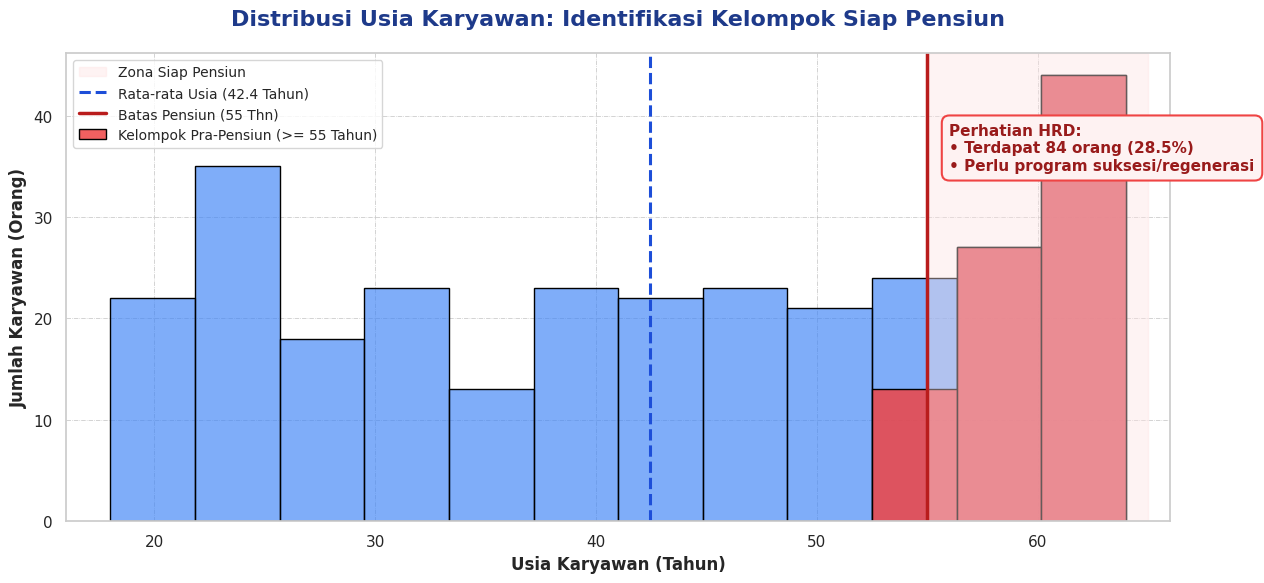

In [50]:
# 1. Menyiapkan data dan memfilter karyawan yang masuk kategori siap pensiun (umur >= 55 tahun)
data_normal = data[data['umur'] < 55]
data_pensiun = data[data['umur'] >= 55].copy()

# 2. Membuat Kanvas Grafik
plt.figure(figsize=(13, 6))

# PERBAIKAN: Mendefinisikan bins yang konsisten untuk kedua layer histogram
bin_edges = np.linspace(data['umur'].min(), data['umur'].max(), 13)

# 3. Menggambar Histogram dengan warna khusus untuk highlight kelompok pensiun
sns.histplot(
    data=data,
    x='umur',
    bins=bin_edges,  # PERBAIKAN: menggunakan bin_edges yang sama
    color='#3b82f6',
    edgecolor='black',
    alpha=0.65,
)

sns.histplot(
    data=data_pensiun,
    x='umur',
    bins=bin_edges,  # PERBAIKAN: menggunakan bin_edges yang sama
    color='#ef4444',
    edgecolor='black',
    alpha=0.85,
    label='Kelompok Pra-Pensiun (>= 55 Tahun)',
)

# 4. Memberikan arsiran latar belakang (shading) pada area siap pensiun
plt.axvspan(
    55,
    data['umur'].max() + 1,
    color='#fee2e2',
    alpha=0.4,
    label='Zona Siap Pensiun',
)

# 5. Perhitungan Metrik Penting
rata_rata_umur = data['umur'].mean()
jumlah_pra_pensiun = len(data_pensiun)
persentase_pensiun = (jumlah_pra_pensiun / len(data)) * 100

# 6. Garis Vertikal Referensi
plt.axvline(
    rata_rata_umur,
    color='#1d4ed8',
    linestyle='--',
    linewidth=2.2,
    label=f'Rata-rata Usia ({rata_rata_umur:.1f} Tahun)',
)
plt.axvline(
    55, color='#b91c1c', linestyle='-', linewidth=2.5, label='Batas Pensiun (55 Thn)'
)

# 7. Kustomisasi Anatomi Grafik
plt.title(
    'Distribusi Usia Karyawan: Identifikasi Kelompok Siap Pensiun',
    loc='center',
    pad=20,
    fontsize=16,
    fontweight='bold',
    color='#1e3a8a',
)
plt.xlabel('Usia Karyawan (Tahun)', fontsize=12, fontweight='bold')
plt.ylabel('Jumlah Karyawan (Orang)', fontsize=12, fontweight='bold')
plt.xlim(16, 66)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5, alpha=0.7)

# 8. Kotak Anotasi Informasi Utama
# PERBAIKAN: Posisi Y anotasi dihitung secara dinamis berdasarkan data
y_ax_max = plt.gca().get_ylim()[1]
plt.text(
    56,
    y_ax_max * 0.75,  # PERBAIKAN: posisi relatif, bukan hardcoded
    f'Perhatian HRD:\n• Terdapat {jumlah_pra_pensiun} orang ({persentase_pensiun:.1f}%)\n• Perlu program suksesi/regenerasi',
    color='#991b1b',
    fontsize=11,
    fontweight='bold',
    bbox=dict(
        boxstyle='round,pad=0.5',
        facecolor='#fef2f2',
        edgecolor='#ef4444',
        linewidth=1.5,
    ),
)

plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()
plt.close()  # PERBAIKAN: menutup figure untuk menghindari memory leak



# 7. VISUALISASI POLA 2: PERBANDINGAN KATEGORIKAL & AGREGASI NUMERIK (`departemen` vs `gaji_numerik`)
## **Metode & Library:** Menggunakan fungsi agregasi `.groupby()` pada Pandas, lalu divisualisasikan dengan **Horizontal Bar Chart (`plt.barh`)** pada Matplotlib.
## **Tujuan Analisis:** Merangkum total pengeluaran gaji bulanan dan jumlah personel pada masing-masing dari 9 departemen untuk melihat divisi mana yang menyerap anggaran terbesar.

=== TABEL AGREGASI PER DEPARTEMEN ===


,departemen,jumlah_karyawan,rata_rata_gaji,total_gaji
4,Marketing,8,6.424485e+06,51395878
2,HR,11,4.842790e+06,53270688
7,R&D,12,5.962359e+06,71548308
6,Produksi,16,4.730101e+06,75681616
3,IT,16,5.501616e+06,88025864
8,Sales,28,5.119028e+06,143332784
5,Operasional,32,4.920124e+06,157443967
1,Finance,37,4.834939e+06,178892728
0,Administrasi,135,4.762740e+06,642969860


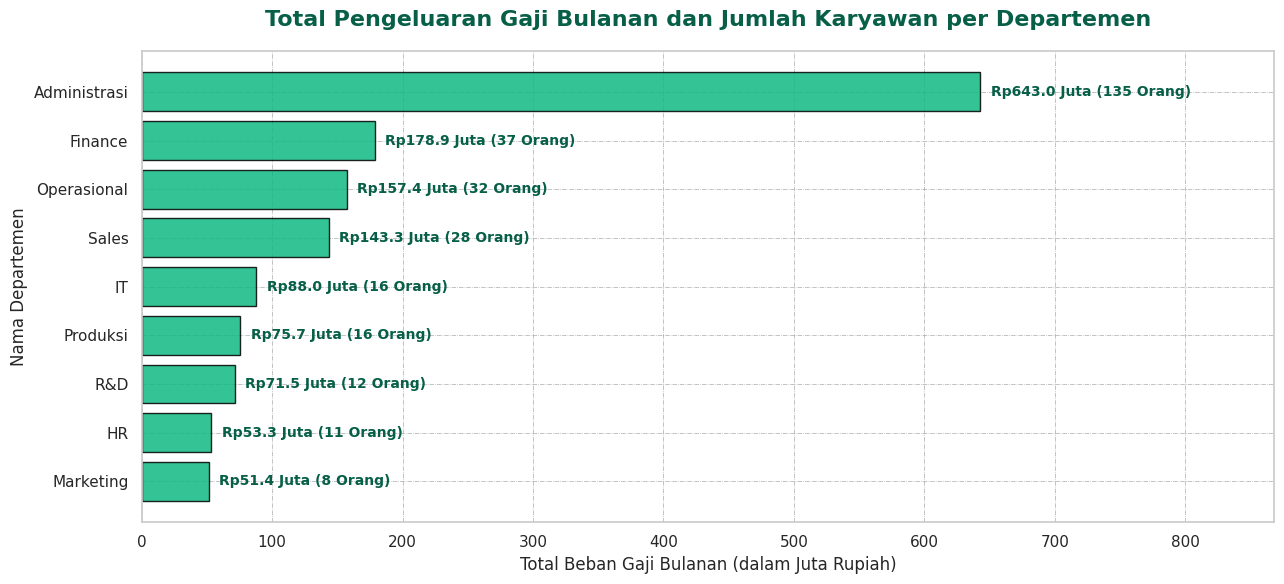

In [40]:
# 1. Melakukan agregasi data per departemen untuk menghitung jumlah karyawan, rata-rata gaji, dan total gaji
#    Fungsi reset_index() mengubah hasil groupby kembali menjadi DataFrame standar
agregasi_departemen = data.groupby('departemen').agg(
    jumlah_karyawan=('id_karyawan', 'count'),
    rata_rata_gaji=('gaji_numerik', 'mean'),
    total_gaji=('gaji_numerik', 'sum')
).reset_index()

# Mengurutkan tabel agregasi berdasarkan 'total_gaji' dari terendah ke tertinggi agar rapi saat diplot horizontal
agregasi_departemen = agregasi_departemen.sort_values(by='total_gaji', ascending=True)

print("=== TABEL AGREGASI PER DEPARTEMEN ===")
display(agregasi_departemen)

# 2. Membuat kanvas Figure berukuran lebar 13 inci dan tinggi 6 inci
plt.figure(figsize=(13, 6))

# 3. Menggambar Horizontal Bar Chart (plt.barh)
#    Nilai total_gaji dibagi 1.000.000 agar sumbu X tampil dalam satuan Juta Rupiah
batang = plt.barh(
    agregasi_departemen['departemen'],
    agregasi_departemen['total_gaji'] / 1000000,
    color='#10b981',
    edgecolor='black',
    alpha=0.85
)

# 4. Menambahkan informasi teks nominal (Juta Rp) dan jumlah orang tepat di ujung kanan setiap batang
for bar, jml_orang in zip(batang, agregasi_departemen['jumlah_karyawan']):
    lebar_batang = bar.get_width()
    posisi_y = bar.get_y() + bar.get_height() / 2
    plt.text(
        lebar_batang + 8,
        posisi_y,
        f'Rp{lebar_batang:.1f} Juta ({jml_orang} Orang)',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='#065f46'
    )

# 5. Kustomisasi Title, Axis Labels, Batas Sumbu X (xlim), dan Grid
plt.title('Total Pengeluaran Gaji Bulanan dan Jumlah Karyawan per Departemen', loc='center', pad=18, fontsize=16, fontweight='bold', color='#065f46')
plt.xlabel('Total Beban Gaji Bulanan (dalam Juta Rupiah)', fontsize=12)
plt.ylabel('Nama Departemen', fontsize=12)

# PERBAIKAN: xlim dihitung dinamis berdasarkan data, bukan hardcoded
max_bar_val = (agregasi_departemen['total_gaji'] / 1_000_000).max()
plt.xlim(0, max_bar_val * 1.35)  # Tambah 35% margin untuk label teks
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)

plt.tight_layout()
plt.show()
plt.close()  # PERBAIKAN: menutup figure untuk menghindari memory leak

# 8. VISUALISASI POLA 3: SEBARAN GAJI & DETEKSI OUTLIER PER JABATAN (`jabatan` vs `gaji_numerik`)
## **Metode & Library:** Kombinasi **Box Plot (`sns.boxplot`)** dan **Strip Plot (`sns.stripplot`)** pada Seaborn.
## **Tujuan Analisis:** Melihat perbedaan rentang gaji antar level jabatan (`Staff`, `Admin`, `Supervisor`, `Manager`), memeriksa nilai tengah (median), serta mendeteksi karyawan yang memiliki gaji di luar batas normal (*outlier*) pada jabatannya.

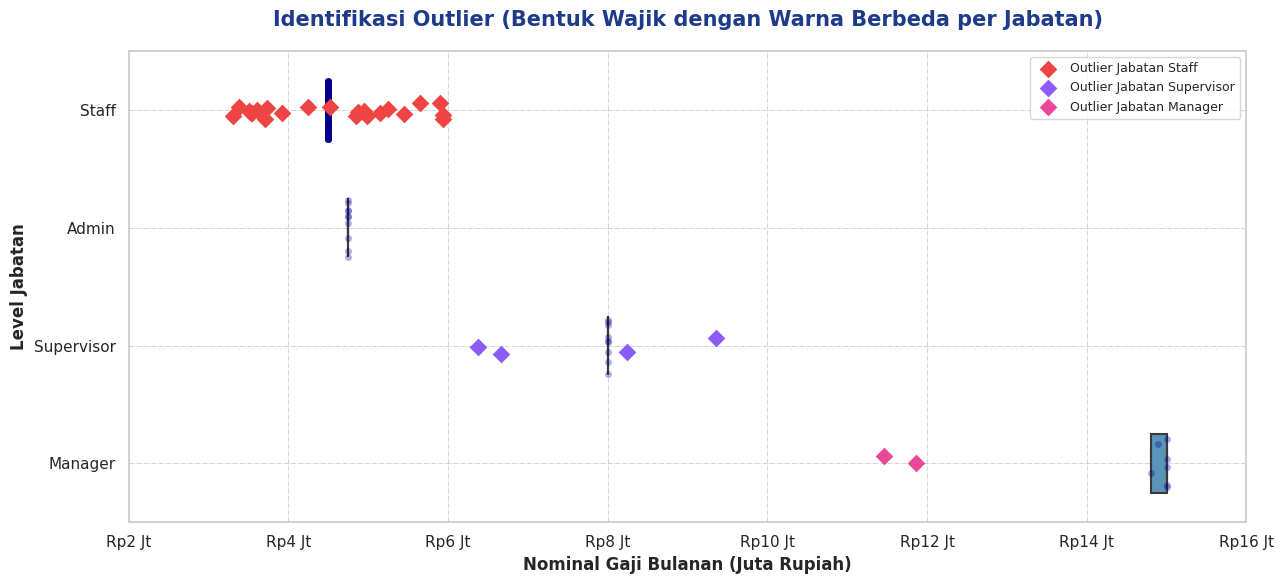


                    LAPORAN ANALISIS DATA OUTLIER (PENCILAN)             
• Total Keseluruhan Karyawan berstatus Outlier: 28 Orang
• Penjelasan Metode: Menggunakan rumus kuartil IQR (Batas Wajar Q1 - 1.5*IQR hingga Q3 + 1.5*IQR).

• Daftar Karyawan dengan Gaji di Luar Kebiasaan (Menyimpang dari Standar Jabatan):


,id_karyawan,nama,jabatan,departemen,gaji_numerik
0,5,Putra Eka,Staff,Produksi,4239552
1,16,Luthfi Susanto Iii,Staff,Administrasi,3602426
2,17,Budi Kurniawan,Staff,Administrasi,5449170
3,68,Rio Wicaksono,Staff,IT,4982097
4,71,Dewi Wijaya,Staff,Finance,5250440
5,77,Agus Halim,Staff,Administrasi,4875851
6,89,Rio Wijaya,Staff,Operasional,3535258
7,105,Putri Sari,Staff,Produksi,4942064
8,106,Ayu Hartati,Staff,Marketing,5895878
9,148,Firmansyah Bayu79,Staff,Operasional,3549082


In [ ]:
# Penjelasan Rumus IQR:
# - Q1 (Kuartil 1 / 25%) : Batas bawah di mana 25% nilai gaji terendah berada.
# - Q3 (Kuartil 3 / 75%) : Batas atas di mana 75% nilai gaji terendah berada.
# - IQR = Q3 - Q1 (Rentang lebar area normal/wajar di tengah).
# - Batas Wajar Bawah = Q1 - 1.5 * IQR -> Gaji di bawah ini dikategorikan Outlier (terlalu rendah).
# - Batas Wajar Atas  = Q3 + 1.5 * IQR -> Gaji di atas ini dikategorikan Outlier (terlalu tinggi).

urutan_jabatan = ['Staff', 'Admin', 'Supervisor', 'Manager']
outliers_list = []

for jab in urutan_jabatan:
    subset = data[data['jabatan'] == jab]
    Q1 = subset['gaji_numerik'].quantile(0.25)
    Q3 = subset['gaji_numerik'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Menyaring karyawan yang gajinya berada di luar batas wajar
    out = subset[(subset['gaji_numerik'] < lower_bound) | (subset['gaji_numerik'] > upper_bound)]
    if not out.empty:
        outliers_list.append(out)

df_outliers = pd.concat(outliers_list)


# =========================================================================
# 3. VISUALISASI GRAFIK: BOX PLOT & OUTLIER WAJIK BERWARNA KHUSUS PER JABATAN
# =========================================================================
plt.figure(figsize=(13, 6))

# Box Plot Utama untuk melihat sebaran kuartil
sns.boxplot(
    data=data,
    x='gaji_numerik',
    y='jabatan',
    order=urutan_jabatan,
    hue='jabatan',
    palette='Blues',
    width=0.5,
    fliersize=0,
    linewidth=1.5
)

# Strip Plot untuk Data Normal (Biru Tua Transparan)
data_normal = data[~data['id_karyawan'].isin(df_outliers['id_karyawan'])]
sns.stripplot(
    data=data_normal,
    x='gaji_numerik',
    y='jabatan',
    order=urutan_jabatan,
    color='darkblue',
    alpha=0.3,
    jitter=0.25,
    size=5
)

# Kamus Gaya: Bentuk ikon diseragamkan Wajik, namun warna dibedakan tiap jabatan
jabatan_outlier_styles = {
    'Staff': {'color': '#ef4444', 'marker': 'D'},      # Merah Terang
    'Admin': {'color': '#f59e0b', 'marker': 'D'},      # Kuning / Oranye
    'Supervisor': {'color': '#8b5cf6', 'marker': 'D'}, # Ungu
    'Manager': {'color': '#ec4899', 'marker': 'D'}     # Pink / Magenta
}

# Melakukan perulangan untuk merender outlier masing-masing jabatan secara spesifik
for jab in urutan_jabatan:
    subset_out = df_outliers[df_outliers['jabatan'] == jab]
    if not subset_out.empty:
        style = jabatan_outlier_styles.get(jab, {'color': 'red', 'marker': 'D'})
        sns.stripplot(
            data=subset_out,
            x='gaji_numerik',
            y='jabatan',
            order=urutan_jabatan,
            color=style['color'],
            marker=style['marker'],
            alpha=1.0,
            jitter=0.08,
            size=9,
            label=f'Outlier Jabatan {jab}'
        )

# Kustomisasi Judul dan Label Sumbu Grafik
plt.title('Identifikasi Outlier (Bentuk Wajik dengan Warna Berbeda per Jabatan)', loc='center', pad=18, fontsize=15, fontweight='bold', color='#1e3a8a')
plt.xlabel('Nominal Gaji Bulanan (Juta Rupiah)', fontsize=12, fontweight='bold')
plt.ylabel('Level Jabatan', fontsize=12, fontweight='bold')

# PERBAIKAN: Mengatur xlim TERLEBIH DAHULU sebelum memformat xticks
# Ini memastikan tick labels sesuai dengan range yang ditampilkan
plt.xlim(2000000, 16000000)

# Format angka sumbu X menjadi Juta Rupiah (Jt) — SETELAH xlim diatur
labels_x, locations_x = plt.xticks()
plt.xticks([x for x in labels_x if x >= 0], [f"Rp{int(x/1000000)} Jt" for x in labels_x if x >= 0])
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5, alpha=0.7)

# PERBAIKAN LEGENDA: Membersihkan duplikasi agar label tampil bersih dan unik
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc='upper right', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()
plt.close()  # PERBAIKAN: menutup figure untuk menghindari memory leak


# =========================================================================
# 4. LAPORAN TABEL HTML INTERAKTIF YANG RAPI
# =========================================================================
print("\n" + "="*73)
print("                    LAPORAN ANALISIS DATA OUTLIER (PENCILAN)             ")
print("="*73)
print(f"• Total Keseluruhan Karyawan berstatus Outlier: {len(df_outliers)} Orang")
print("• Penjelasan Metode: Menggunakan rumus kuartil IQR (Batas Wajar Q1 - 1.5*IQR hingga Q3 + 1.5*IQR).\n")
print("• Daftar Karyawan dengan Gaji di Luar Kebiasaan (Menyimpang dari Standar Jabatan):")

# Menampilkan tabel data outlier secara interaktif dan rapi di Colab
display(df_outliers[['id_karyawan', 'nama', 'jabatan', 'departemen', 'gaji_numerik']].reset_index(drop=True))
print("="*73)

# 9. VISUAL LABELING: MEMBENTUK KOLOM LABEL BARU DARI POLA GRAFIK
## Berdasarkan temuan pola dari ketiga visualisasi di atas (batas usia pra-pensiun pada Histogram, ketimpangan ukuran departemen pada Bar Chart, serta batas lonjakan gaji Rp6.000.000 antara Staff/Admin dengan Supervisor/Manager pada Box Plot), kita membuat fungsi logika untuk melahirkan **3 atribut label baru**:
1. **`label_segmen_karir`**: Klasifikasi profil karir karyawan berdasarkan kuadran `umur` dan `gaji_numerik`.
2. **`label_zona_asal`**: Pengelompokan 20 `kota_asal` menjadi 3 zona geografis utama.
3. **`label_skala_divisi`**: Pengelompokan ukuran `departemen` berdasarkan jumlah personelnya.

In [42]:
# -------------------------------------------------------------------------
# 1. FUNGSI PEMBENTUKAN LABEL SEGMEN KARIR (DARI KUADRAN UMUR & GAJI)
# -------------------------------------------------------------------------
def bentuk_label_karir(baris):
    """
    Fungsi untuk melabeli setiap baris karyawan ke dalam 5 segmen karir
    berdasarkan garis batas (threshold) visual umur dan gaji_numerik.
    """
    umur = baris['umur']
    gaji = baris['gaji_numerik']

    # Segmen 1: Karyawan yang telah memasuki usia pra-pensiun (>= 55 tahun)
    if umur >= 55:
        return '1. Siap Pensiun (>=55 Thn)'

    # Segmen 2: Karyawan muda (< 35 tahun) yang sudah menembus gaji level pimpinan (>= Rp6 Juta)
    elif umur < 35 and gaji >= 6000000:
        return '2. Fast-Track (<35 Thn, Gaji Tinggi)'

    # Segmen 3: Karyawan usia matang (35-54 tahun) yang berada di level pimpinan (>= Rp6 Juta)
    elif umur >= 35 and gaji >= 6000000:
        return '3. Pimpinan / Senior Mapan'

    # Segmen 4: Karyawan senior (45-54 tahun) namun gajinya masih berada di level dasar (< Rp6 Juta)
    elif umur >= 45 and gaji < 6000000:
        return '4. Stagnan Senior (45-54 Thn, Staff/Admin)'

    # Segmen 5: Karyawan operasional usia produktif (< 45 tahun) dengan gaji reguler (< Rp6 Juta)
    else:
        return '5. Operasional Reguler (<45 Thn)'


# -------------------------------------------------------------------------
# 2. FUNGSI PEMBENTUKAN LABEL ZONA WILAYAH KOTA ASAL
# -------------------------------------------------------------------------
def bentuk_label_zona(kota):
    """
    Fungsi untuk mengelompokkan 20 nama kota asal menjadi 3 zona geografis
    guna memudahkan analisis demografi perantau oleh tim HR.
    """
    if pd.isna(kota):
        return 'Tidak Diketahui'

    kota = str(kota).strip().title()
    kota_jabodetabek = ['Jakarta', 'Bogor', 'Depok', 'Tangerang', 'Bekasi']
    kota_luar_jawa = ['Palembang', 'Banjarmasin', 'Makassar', 'Manado', 'Medan', 'Padang', 'Pekanbaru']

    if kota in kota_jabodetabek:
        return 'Zona Jabodetabek'
    elif kota in kota_luar_jawa:
        return 'Zona Luar Pulau Jawa'
    else:
        return 'Zona Jawa (Non-Jabodetabek)'


# -------------------------------------------------------------------------
# 3. FUNGSI PEMBENTUKAN LABEL SKALA DIVISI (DEPARTEMEN)
# -------------------------------------------------------------------------
def bentuk_label_divisi(dept):
    """
    Fungsi untuk mengelompokkan departemen berdasarkan skala jumlah personelnya
    sesuai hasil temuan pada Horizontal Bar Chart.
    """
    if dept == 'Administrasi':
        return 'Divisi Utama (>100 Orang)'
    elif dept in ['Finance', 'Operasional', 'Sales']:
        return 'Divisi Menengah (25-50 Orang)'
    else:
        return 'Divisi Spesialis (<25 Orang)'


# Menerapkan ketiga fungsi ke dalam DataFrame 'data'
data['label_segmen_karir'] = data.apply(bentuk_label_karir, axis=1)
data['label_zona_asal'] = data['kota_asal'].apply(bentuk_label_zona)
data['label_skala_divisi'] = data['departemen'].apply(bentuk_label_divisi)

print("Ketiga kolom label baru berhasil dibentuk dari hasil eksplorasi visual.")

# Menampilkan frekuensi hasil pelabelan
print("\n=== DISTRIBUSI LABEL SEGMEN KARIR ===")
print(data['label_segmen_karir'].value_counts().sort_index())

print("\n=== DISTRIBUSI LABEL ZONA ASAL ===")
print(data['label_zona_asal'].value_counts())

print("\n=== DISTRIBUSI LABEL SKALA DIVISI ===")
print(data['label_skala_divisi'].value_counts())

Ketiga kolom label baru berhasil dibentuk dari hasil eksplorasi visual.

=== DISTRIBUSI LABEL SEGMEN KARIR ===
label_segmen_karir
1. Siap Pensiun (>=55 Thn)                     84
2. Fast-Track (<35 Thn, Gaji Tinggi)            5
3. Pimpinan / Senior Mapan                      8
4. Stagnan Senior (45-54 Thn, Staff/Admin)     51
5. Operasional Reguler (<45 Thn)              147
Name: count, dtype: int64

=== DISTRIBUSI LABEL ZONA ASAL ===
label_zona_asal
Zona Jawa (Non-Jabodetabek)    143
Zona Jabodetabek                93
Zona Luar Pulau Jawa            59
Name: count, dtype: int64

=== DISTRIBUSI LABEL SKALA DIVISI ===
label_skala_divisi
Divisi Utama (>100 Orang)        135
Divisi Menengah (25-50 Orang)     97
Divisi Spesialis (<25 Orang)      63
Name: count, dtype: int64


# 10. VISUALISASI POLA 4: PETA KORELASI & HASIL VISUAL LABELING (`umur` vs `gaji_numerik`)
## **Metode & Library:** Menggunakan **Scatter Plot Statis (`sns.scatterplot`)** untuk laporan dokumen dan **Scatter Plot Interaktif (`px.scatter`)** untuk eksplorasi detail nama karyawan di Google Colab.
## **Tujuan Analisis:** Memetakan 2 variabel numerik (`umur` pada sumbu X dan `gaji_numerik` pada sumbu Y) sekaligus menampilkan pemisahan warna dari kolom **`label_segmen_karir`** yang baru saja kita bentuk.

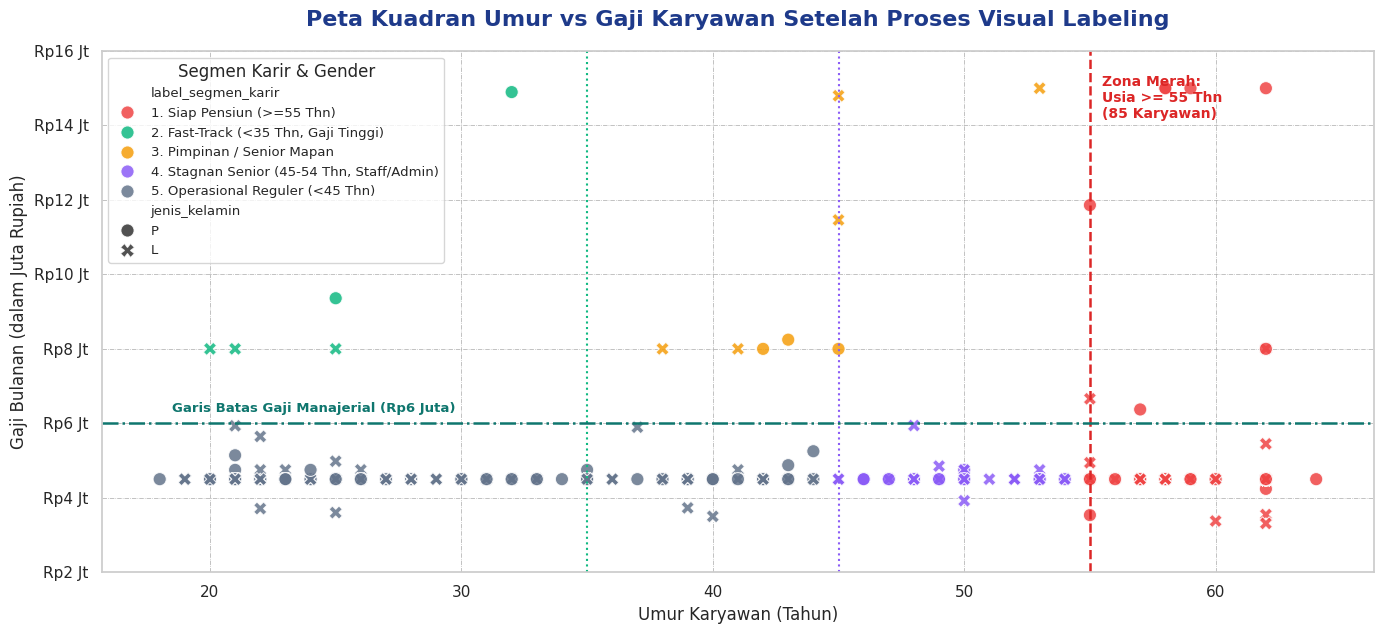

In [43]:
  # A. SCATTER PLOT STATIS DENGAN ANATOMI MATPLOTLIB & SEABORN
plt.figure(figsize=(14, 6.5))

# Mendefinisikan palet warna khusus untuk masing-masing dari 5 segmen karir
palet_segmen = {
    '1. Siap Pensiun (>=55 Thn)': '#ef4444',                 # Merah
    '2. Fast-Track (<35 Thn, Gaji Tinggi)': '#10b981',       # Hijau
    '3. Pimpinan / Senior Mapan': '#f59e0b',                 # Oranye
    '4. Stagnan Senior (45-54 Thn, Staff/Admin)': '#8b5cf6', # Ungu
    '5. Operasional Reguler (<45 Thn)': '#64748b'            # Abu-abu kebiruan
}

# Menggambar Scatter Plot dengan pembeda warna (hue) berdasarkan 'label_segmen_karir'
# dan pembeda bentuk marker (style) berdasarkan 'jenis_kelamin'
sns.scatterplot(
    data=data,
    x='umur',
    y='gaji_numerik',
    hue='label_segmen_karir',
    hue_order=list(palet_segmen.keys()),
    palette=palet_segmen,
    style='jenis_kelamin',
    s=90,        # Ukuran titik marker
    alpha=0.85   # Transparansi titik
)

# Menambahkan garis pembatas kuadran (Threshold Lines) yang menjadi dasar pembentukan label
plt.axvline(55, color='#dc2626', linestyle='--', linewidth=1.8)
plt.axvline(35, color='#10b981', linestyle=':', linewidth=1.5)
plt.axvline(45, color='#8b5cf6', linestyle=':', linewidth=1.5)
plt.axhline(6000000, color='#0f766e', linestyle='-.', linewidth=1.8)

# Mengatur skala angka sumbu Y (yticks) agar tampil dalam satuan Juta Rupiah
plt.ylim(ymin=2500000, ymax=16000000)
labels_y, locations_y = plt.yticks()
plt.yticks(labels_y, [f"Rp{int(y/1000000)} Jt" for y in labels_y])

# Menambahkan Judul, Label Sumbu, Grid, dan Keterangan Teks (plt.text)
plt.title('Peta Kuadran Umur vs Gaji Karyawan Setelah Proses Visual Labeling', loc='center', pad=18, fontsize=16, fontweight='bold', color='#1e3a8a')
plt.xlabel('Umur Karyawan (Tahun)', fontsize=12)
plt.ylabel('Gaji Bulanan (dalam Juta Rupiah)', fontsize=12)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)

plt.text(55.5, 14200000, 'Zona Merah:\nUsia >= 55 Thn\n(85 Karyawan)', color='#dc2626', fontsize=10, fontweight='bold')
plt.text(18.5, 6300000, 'Garis Batas Gaji Manajerial (Rp6 Juta)', color='#0f766e', fontsize=9.5, fontweight='bold')

plt.legend(title='Segmen Karir & Gender', loc='upper left', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()

In [44]:
# B. SCATTER PLOT INTERAKTIF MENGGUNAKAN PLOTLY EXPRESS
# Arahkan kursor (hover) ke titik mana saja untuk melihat Nama, Jabatan, Departemen, dan Kota Asal karyawan
fig_interaktif = px.scatter(
    data,
    x='umur',
    y='gaji_numerik',
    color='label_segmen_karir',
    symbol='jenis_kelamin',
    hover_name='nama',
    hover_data=['id_karyawan', 'departemen', 'jabatan', 'kota_asal', 'label_zona_asal', 'gaji'],
    color_discrete_map=palet_segmen,
    title='Eksplorasi Interaktif: Peta 5 Segmen Karir Karyawan (Arahkan Kursor ke Titik Data)',
    labels={
        'umur': 'Umur Karyawan (Tahun)',
        'gaji_numerik': 'Gaji Bulanan (Rupiah)',
        'label_segmen_karir': 'Segmen Karir',
        'jenis_kelamin': 'Gender'
    },
    height=550
)

fig_interaktif.update_traces(marker=dict(size=10, opacity=0.85))
fig_interaktif.show()

# 11. HASIL AKHIR DAN EXPORT DATA BERLABEL

In [45]:
# Memeriksa kembali struktur seluruh kolom setelah proses transformasi dan visual labeling
data.info()

# Menampilkan 20 baris pertama dari dataset yang kini telah memiliki kolom metrik dan label baru
display(data.head(20))

# Menyimpan dataset hasil akhir ke dalam Google Drive
file_output = '/content/drive/MyDrive/Data Maining 2026/Data Visualization/dataset_karyawan_300_berlabel_final.xlsx'

data.to_excel(
    file_output,
    index=False
)

print("Dataset lengkap beserta label hasil visualisasi berhasil disimpan.")
print("Lokasi penyimpanan:", file_output)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id_karyawan         295 non-null    int64 
 1   nama                295 non-null    object
 2   jenis_kelamin       295 non-null    object
 3   umur                295 non-null    int64 
 4   departemen          295 non-null    object
 5   jabatan             295 non-null    object
 6   kota_asal           295 non-null    object
 7   gaji                295 non-null    object
 8   gaji_numerik        295 non-null    int64 
 9   gaji_tahunan        295 non-null    int64 
 10  label_segmen_karir  295 non-null    object
 11  label_zona_asal     295 non-null    object
 12  label_skala_divisi  295 non-null    object
dtypes: int64(4), object(9)
memory usage: 30.1+ KB


,id_karyawan,nama,jenis_kelamin,umur,departemen,jabatan,kota_asal,gaji,gaji_numerik,gaji_tahunan,label_segmen_karir,label_zona_asal,label_skala_divisi
0,1,Slamet Pratama Ii,P,50,R&D,Admin,Malang,Rp4.750.000,4750000,57000000,"4. Stagnan Senior (45-54 Thn, Staff/Admin)",Zona Jawa (Non-Jabodetabek),Divisi Spesialis (<25 Orang)
1,2,Nina Putra,P,22,Sales,Staff,Palembang,Rp4.500.000,4500000,54000000,5. Operasional Reguler (<45 Thn),Zona Luar Pulau Jawa,Divisi Menengah (25-50 Orang)
2,3,Luthfi Kusuma Iii,P,25,Finance,Staff,Manado,Rp4.500.000,4500000,54000000,5. Operasional Reguler (<45 Thn),Zona Luar Pulau Jawa,Divisi Menengah (25-50 Orang)
3,4,Rio Iskandar,P,47,Administrasi,Staff,Makassar,Rp4.500.000,4500000,54000000,"4. Stagnan Senior (45-54 Thn, Staff/Admin)",Zona Luar Pulau Jawa,Divisi Utama (>100 Orang)
4,5,Putra Eka,P,62,Produksi,Staff,Palembang,Rp4.239.552,4239552,50874624,1. Siap Pensiun (>=55 Thn),Zona Luar Pulau Jawa,Divisi Spesialis (<25 Orang)
5,6,Tito Halim,L,45,R&D,Staff,Pontianak,Rp4.500.000,4500000,54000000,"4. Stagnan Senior (45-54 Thn, Staff/Admin)",Zona Jawa (Non-Jabodetabek),Divisi Spesialis (<25 Orang)
6,7,Siti Halim,P,42,Administrasi,Staff,Malang,Rp4.500.000,4500000,54000000,5. Operasional Reguler (<45 Thn),Zona Jawa (Non-Jabodetabek),Divisi Utama (>100 Orang)
7,8,Agus Halim,L,40,Finance,Staff,Jakarta,Rp4.500.000,4500000,54000000,5. Operasional Reguler (<45 Thn),Zona Jabodetabek,Divisi Menengah (25-50 Orang)
8,9,Eka Kurniawan,P,28,Administrasi,Staff,Depok,Rp4.500.000,4500000,54000000,5. Operasional Reguler (<45 Thn),Zona Jabodetabek,Divisi Utama (>100 Orang)
9,10,Wicaksono Agus,P,23,Administrasi,Staff,Pontianak,Rp4.500.000,4500000,54000000,5. Operasional Reguler (<45 Thn),Zona Jawa (Non-Jabodetabek),Divisi Utama (>100 Orang)


Dataset lengkap beserta label hasil visualisasi berhasil disimpan.
Lokasi penyimpanan: /content/drive/MyDrive/Data Maining 2026/Data Visualization/dataset_karyawan_300_berlabel_final.xlsx
